# Decision-curve analysis

Evaluates the clinical net benefit of each model on the untouched temporal test set, compared with treating everybody and treating nobody.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import sys
import yaml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path.cwd().parent / 'src'))

from icare_risk.data.audit import load_admission_file
from icare_risk.evaluation.decision_curve import (
    evaluate_decision_curves,
    decision_curve_summary,
    plot_decision_curves,
)

In [3]:
CONFIG_PATH = Path('../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as f:
    config = yaml.safe_load(f)

prediction_path = (
    Path(config['outputs']['prediction_directory'])
    / 'admission_predictions.parquet'
)
predictions = load_admission_file(prediction_path)

target = config['columns']['target']
target_mapping = config.get(
    'target_mapping',
    config.get('analysis', {}).get('target_mapping', {}),
)
prediction_columns = [
    column for column in predictions.columns if column.endswith('_prob')
]

if not prediction_columns:
    raise ValueError('No *_prob columns found in the prediction table.')

test_mask = (
    predictions['split'].eq('test')
    if 'split' in predictions.columns else None
)

print(f'Prediction rows: {len(predictions):,}')
print(f'Models: {prediction_columns}')
print(f'Test rows: {int(test_mask.sum()):,}' if test_mask is not None else 'No split column found')

Prediction rows: 10,000
Models: ['lr_kim_score_prob', 'lr_all_scores_prob', 'lr_clinical_baseline_prob', 'xgb_kim_score_prob', 'xgb_all_scores_prob', 'xgb_clinical_baseline_prob']
Test rows: 2,483


Thresholds represent the predicted probability at which the clinical action would be taken. Adjust this range after defining the acceptable trade-off between missed ESBL cases and unnecessary broad-spectrum treatment.

In [4]:
thresholds = np.linspace(0.01, 0.50, 100)

curves = evaluate_decision_curves(
    predictions,
    target_column=target,
    prediction_columns=prediction_columns,
    thresholds=thresholds,
    subset=test_mask,
    target_mapping=target_mapping,
)

summary = decision_curve_summary(curves)
display(summary)

,model,best_threshold,maximum_net_benefit,threshold_min_better_than_references,threshold_max_better_than_references
0,lr_all_scores,0.01,0.196557,0.054545,0.203030
1,lr_clinical_baseline,0.01,0.196557,0.163434,0.188182
2,lr_kim_score,0.01,0.196557,0.163434,0.203030
3,xgb_all_scores,0.01,0.196557,0.074343,0.217879
4,xgb_clinical_baseline,0.01,0.196557,0.049596,0.381212
5,xgb_kim_score,0.01,0.196557,0.104040,0.183232


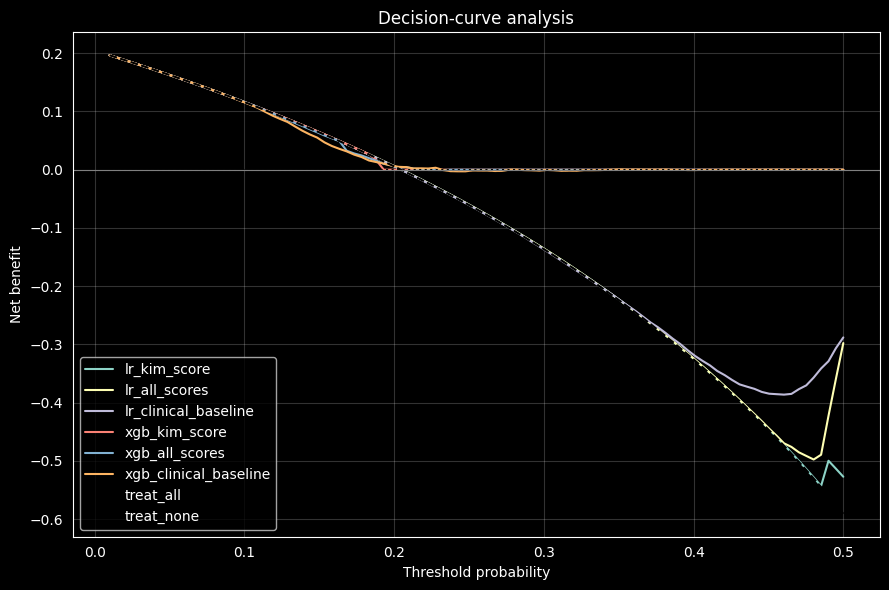

In [5]:
ax = plot_decision_curves(curves)
plt.tight_layout()
plt.show()

In [6]:
output_dir = Path(
    config['outputs'].get(
        'decision_curve_directory',
        'results/decision_curve',
    )
)
output_dir.mkdir(parents=True, exist_ok=True)

curves.to_csv(output_dir / 'decision_curve_values.csv', index=False)
summary.to_csv(output_dir / 'decision_curve_summary.csv', index=False)
ax.get_figure().savefig(
    output_dir / 'decision_curve_plot.png',
    dpi=200,
    bbox_inches='tight',
)
print(f'Saved decision-curve results to {output_dir}')

Saved decision-curve results to results/decision_curve
